# Fraud Detection in Credit Card Transactions

**Objective:** identify fraudulent transactions using anomaly detection and supervised learning.
**Tools:** Python, Scikit-Learn, XGBoost, Pandas (plus imbalanced-learn, Matplotlib, Streamlit).

Pipeline: load the Kaggle credit card dataset -> preprocess -> balance the training data -> Isolation Forest and Local Outlier Factor (unsupervised) -> XGBoost classifier -> ROC curve, precision-recall curve, confusion matrix -> save the model for the Streamlit app.

**Run it in Google Colab:** Runtime > Run all. The dataset downloads automatically. The last cell downloads the model and charts as a zip.

In [1]:
!pip install -q xgboost imbalanced-learn

In [2]:
import os, json, random, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUT, MODELS, DATA = "outputs", "models", "data"
for d in (OUT, MODELS, DATA): os.makedirs(d, exist_ok=True)

## 1. Load the Kaggle credit card dataset

The data is the well-known *Credit Card Fraud Detection* dataset (ULB Machine Learning Group, on Kaggle as `mlg-ulb/creditcardfraud`): 284,807 card transactions made by European cardholders over two days in September 2013, of which 492 are fraud. Features `V1`-`V28` are anonymized PCA components; `Amount` and `Time` are the only raw fields; `Class` is 1 for fraud.

The cell below uses `data/creditcard.csv` if it exists; otherwise it downloads a copy of the same dataset from GitHub. To use the original instead, download `creditcard.csv` from Kaggle and place it in `data/`.

In [3]:
CSV = f"{DATA}/creditcard.csv"
MIRROR = "https://raw.githubusercontent.com/nsethi31/Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv"
if not os.path.exists(CSV):
    print("Downloading dataset ...")
    urllib.request.urlretrieve(MIRROR, CSV)

raw = pd.read_csv(CSV)
print("rows, columns:", raw.shape)
print("missing values:", int(raw.isna().sum().sum()), "| duplicate rows:", int(raw.duplicated().sum()))
vc = raw["Class"].value_counts()
print(f"legitimate: {vc[0]:,}   fraud: {vc[1]:,}   fraud rate: {vc[1] / len(raw) * 100:.3f}%")
raw.head()

rows, columns: (284807, 31)


missing values: 0 | duplicate rows: 1081
legitimate: 284,315   fraud: 492   fraud rate: 0.173%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


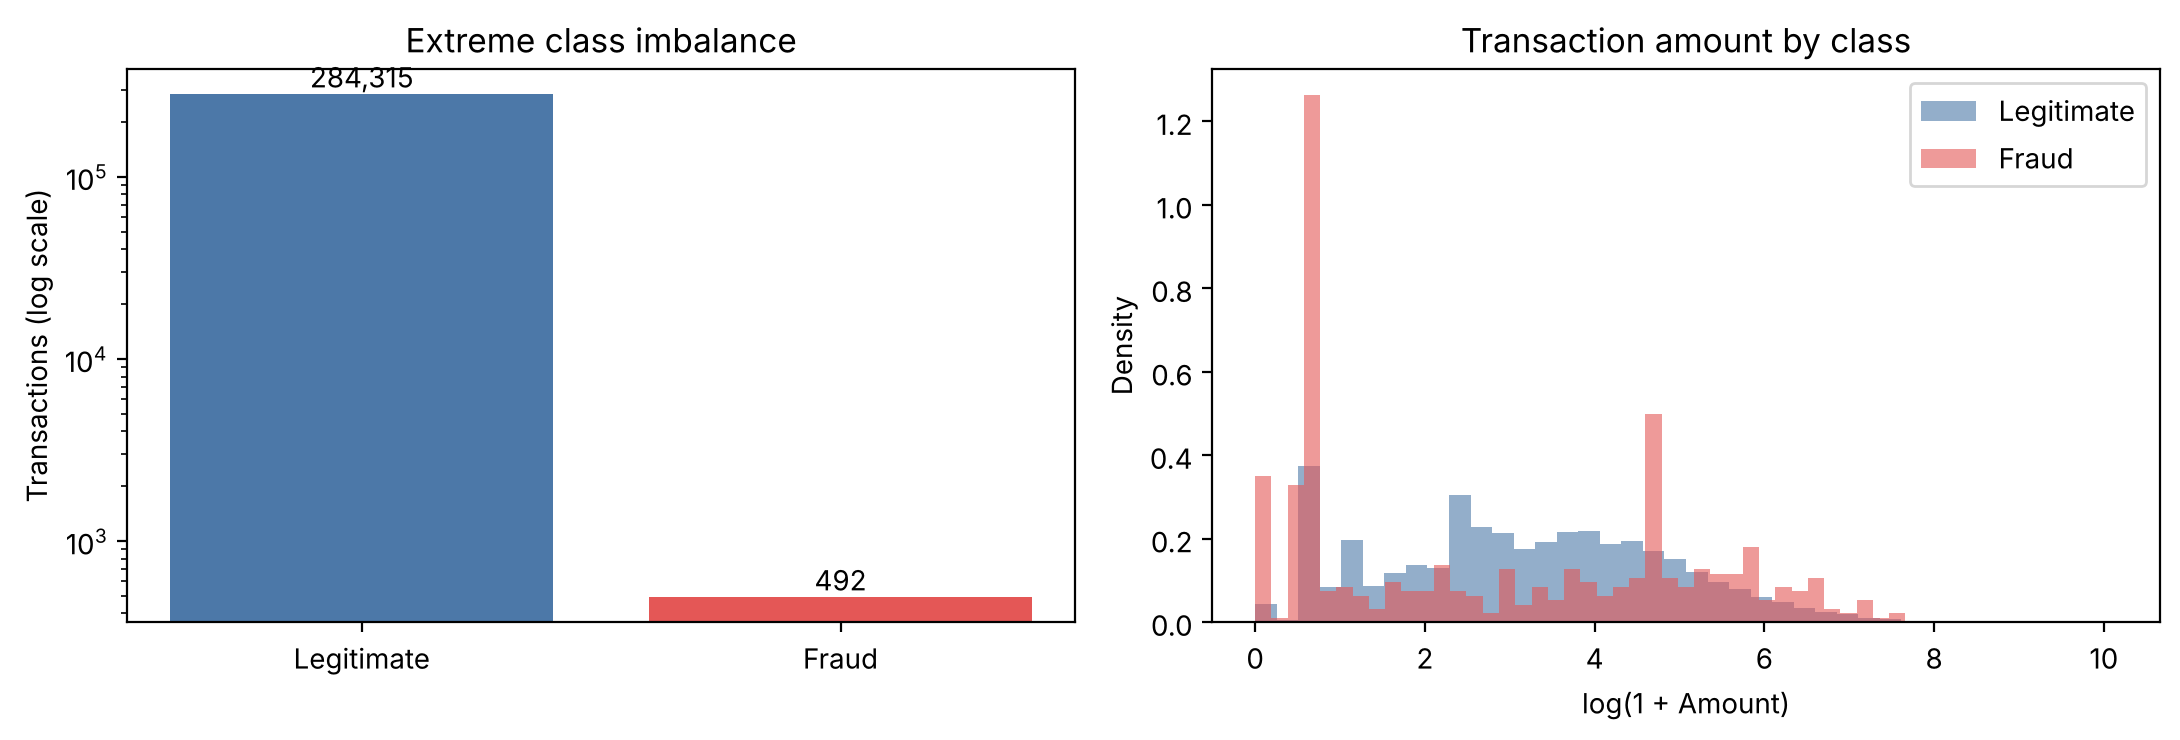

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(["Legitimate", "Fraud"], [vc[0], vc[1]], color=["#4C78A8", "#E45756"])
ax[0].set_yscale("log"); ax[0].set_ylabel("Transactions (log scale)"); ax[0].set_title("Extreme class imbalance")
for i, v in enumerate([vc[0], vc[1]]): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
for c, name, col in [(0, "Legitimate", "#4C78A8"), (1, "Fraud", "#E45756")]:
    ax[1].hist(np.log1p(raw.loc[raw["Class"] == c, "Amount"]), bins=40, alpha=.6, density=True, label=name, color=col)
ax[1].set_xlabel("log(1 + Amount)"); ax[1].set_ylabel("Density"); ax[1].set_title("Transaction amount by class"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/01_class_balance.png", dpi=150); plt.show()

## 2. Preprocess

* Remove the exact duplicate rows.
* Amount is highly skewed, so use `log(1 + Amount)` and standardize it. `V1`-`V28` are already PCA-scaled. `Time` (seconds since the first transaction) is dropped, since it only spans two days and would not generalize.
* **Stratified 80/20 train/test split.** The test set keeps the real fraud rate and is never touched during training, balancing, or threshold selection.

In [5]:
df = raw.drop_duplicates().reset_index(drop=True)
print(f"removed {len(raw) - len(df):,} duplicate rows -> {len(df):,} left, {int(df['Class'].sum())} fraud")

df["Amount_log"] = np.log1p(df["Amount"])
FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount_log"]
X, y = df[FEATURES], df["Class"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

scaler = StandardScaler().fit(X_train[["Amount_log"]])       # fit on training data only
X_train, X_test = X_train.copy(), X_test.copy()
X_train["Amount_log"] = scaler.transform(X_train[["Amount_log"]])
X_test["Amount_log"] = scaler.transform(X_test[["Amount_log"]])
fraud_rate = float(y_train.mean())
print(f"train: {X_train.shape}, fraud {int(y_train.sum())} | test: {X_test.shape}, fraud {int(y_test.sum())}")

removed 1,081 duplicate rows -> 283,726 left, 473 fraud


train: (226980, 29), fraud 378 | test: (56746, 29), fraud 95


## 3. Unsupervised anomaly detection: Isolation Forest and Local Outlier Factor

Both models are fitted **without using the fraud labels**. A transaction that is easy to isolate (Isolation Forest) or sits in a much sparser region than its neighbours (LOF) gets a high anomaly score. Labels are used only afterwards, to measure how well that score separates fraud from legitimate transactions.

LOF compares every transaction with its nearest neighbours, which is expensive on 220,000 rows, so it is fitted on a random sample of 30,000 training transactions.

In [6]:
def evaluate(name, y_true, score, pred):
    return {
        "Model": name,
        "ROC_AUC": float(roc_auc_score(y_true, score)),
        "PR_AUC": float(average_precision_score(y_true, score)),
        "Precision": float(precision_score(y_true, pred, zero_division=0)),
        "Recall": float(recall_score(y_true, pred)),
        "F1": float(f1_score(y_true, pred)),
    }

results, scores = [], {}

iso = IsolationForest(n_estimators=200, contamination=fraud_rate, random_state=SEED, n_jobs=-1).fit(X_train)
s_iso = -iso.score_samples(X_test)                    # higher = more anomalous
scores["Isolation Forest"] = s_iso
results.append(evaluate("Isolation Forest", y_test, s_iso, (iso.predict(X_test) == -1).astype(int)))

rng = np.random.RandomState(SEED)
sub = rng.choice(len(X_train), size=30000, replace=False)
lof = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=fraud_rate, n_jobs=-1).fit(X_train.iloc[sub])
s_lof = -lof.score_samples(X_test)
scores["Local Outlier Factor"] = s_lof
results.append(evaluate("Local Outlier Factor", y_test, s_lof, (lof.predict(X_test) == -1).astype(int)))
pd.DataFrame(results).round(4)

,Model,ROC_AUC,PR_AUC,Precision,Recall,F1
0,Isolation Forest,0.9396,0.1265,0.2243,0.2526,0.2376
1,Local Outlier Factor,0.6920,0.0088,0.0211,0.0211,0.0211


## 4. Balance the training data (SMOTE) and train XGBoost

Only 0.17% of transactions are fraud, so a classifier can reach 99.8% accuracy by predicting "legitimate" every time. To avoid that:

* A validation set (15% of the training data) is held out first, with the real class ratio.
* **SMOTE** creates synthetic fraud examples in the remaining training data until both classes are the same size. SMOTE is applied **only to training data**, never to validation or test data.
* XGBoost trains on the balanced data, with early stopping on the *unbalanced* validation set (average precision).

In [7]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
print("before SMOTE:", np.bincount(y_tr))
X_bal, y_bal = SMOTE(random_state=SEED).fit_resample(X_tr, y_tr)
print("after SMOTE: ", np.bincount(y_bal))

xgb = XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                    tree_method="hist", eval_metric="aucpr", early_stopping_rounds=20,
                    random_state=SEED, n_jobs=-1)
xgb.fit(X_bal, y_bal, eval_set=[(X_val, y_val)], verbose=False)
print("best iteration:", xgb.best_iteration)

before SMOTE: [192612    321]


after SMOTE:  [192612 192612]


best iteration: 49


### Choosing the decision threshold

The default threshold of 0.5 is rarely best for fraud. The threshold that maximizes F1 is chosen on the **validation set** (not the test set), then applied to the test set.

In [8]:
p_val = xgb.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
THRESHOLD = float(thr[np.argmax(f1s)])
print(f"threshold chosen on validation set: {THRESHOLD:.4f}")

p_test = xgb.predict_proba(X_test)[:, 1]
scores["XGBoost"] = p_test
results.append(evaluate("XGBoost (threshold 0.5)", y_test, p_test, (p_test >= 0.5).astype(int)))
results.append(evaluate(f"XGBoost (tuned threshold {THRESHOLD:.2f})", y_test, p_test, (p_test >= THRESHOLD).astype(int)))
res_df = pd.DataFrame(results).round(4)
res_df

threshold chosen on validation set: 0.9760


,Model,ROC_AUC,PR_AUC,Precision,Recall,F1
0,Isolation Forest,0.9396,0.1265,0.2243,0.2526,0.2376
1,Local Outlier Factor,0.6920,0.0088,0.0211,0.0211,0.0211
2,XGBoost (threshold 0.5),0.9640,0.7660,0.2194,0.8316,0.3473
3,XGBoost (tuned threshold 0.98),0.9640,0.7660,0.9130,0.6632,0.7683


## 5. ROC curve, precision-recall curve and confusion matrix

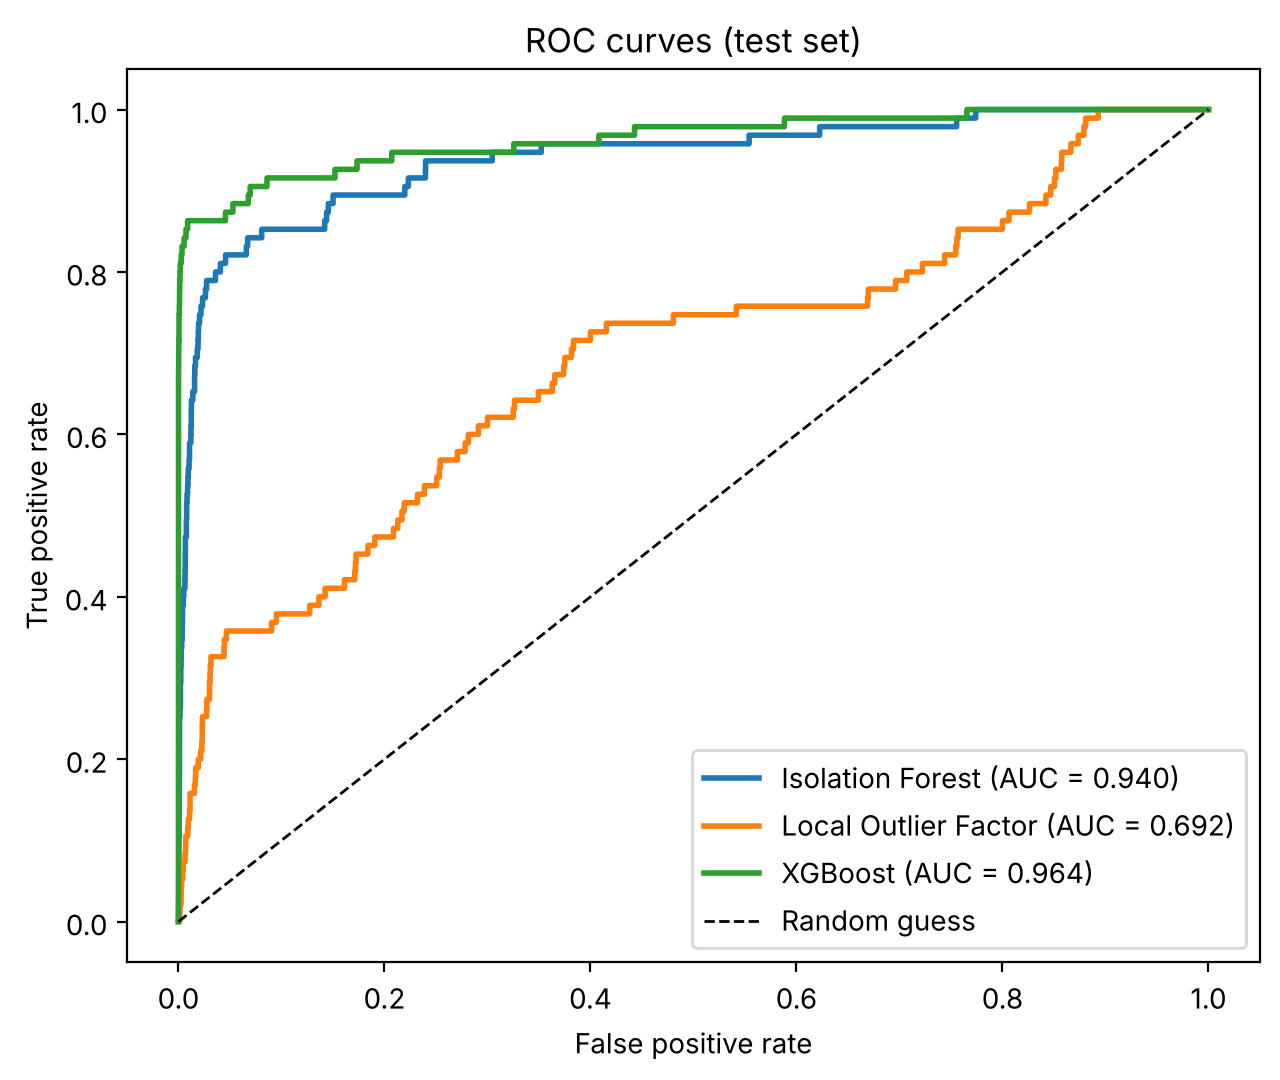

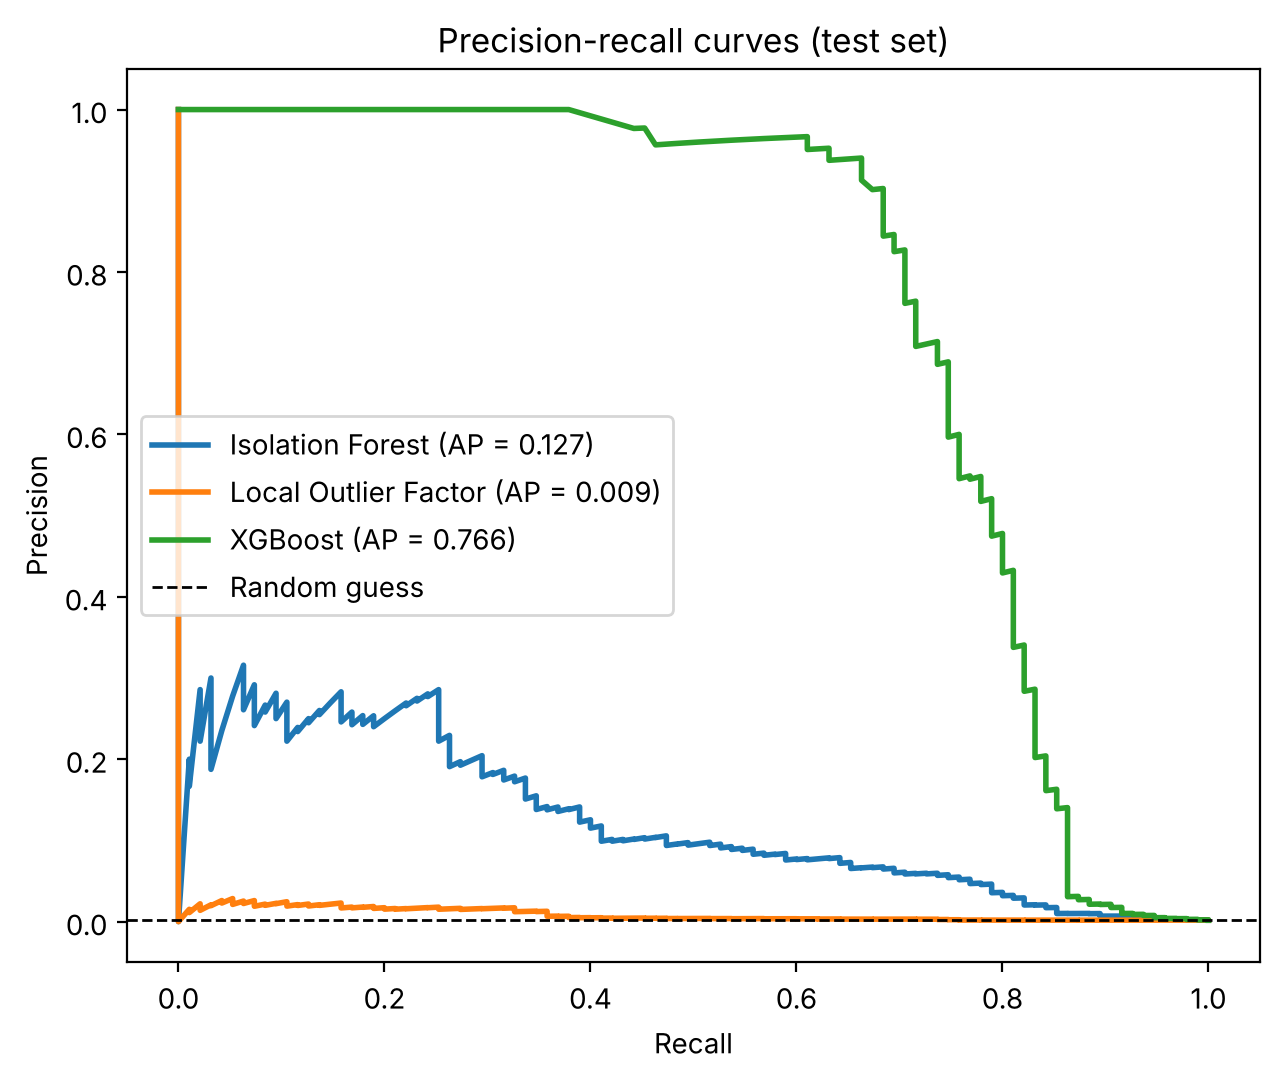

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves (test set)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/02_roc_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    ax.plot(r, p, lw=2, label=f"{name} (AP = {average_precision_score(y_test, s):.3f})")
ax.axhline(y_test.mean(), color="k", ls="--", lw=1, label="Random guess")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall curves (test set)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/03_precision_recall.png", dpi=150); plt.show()

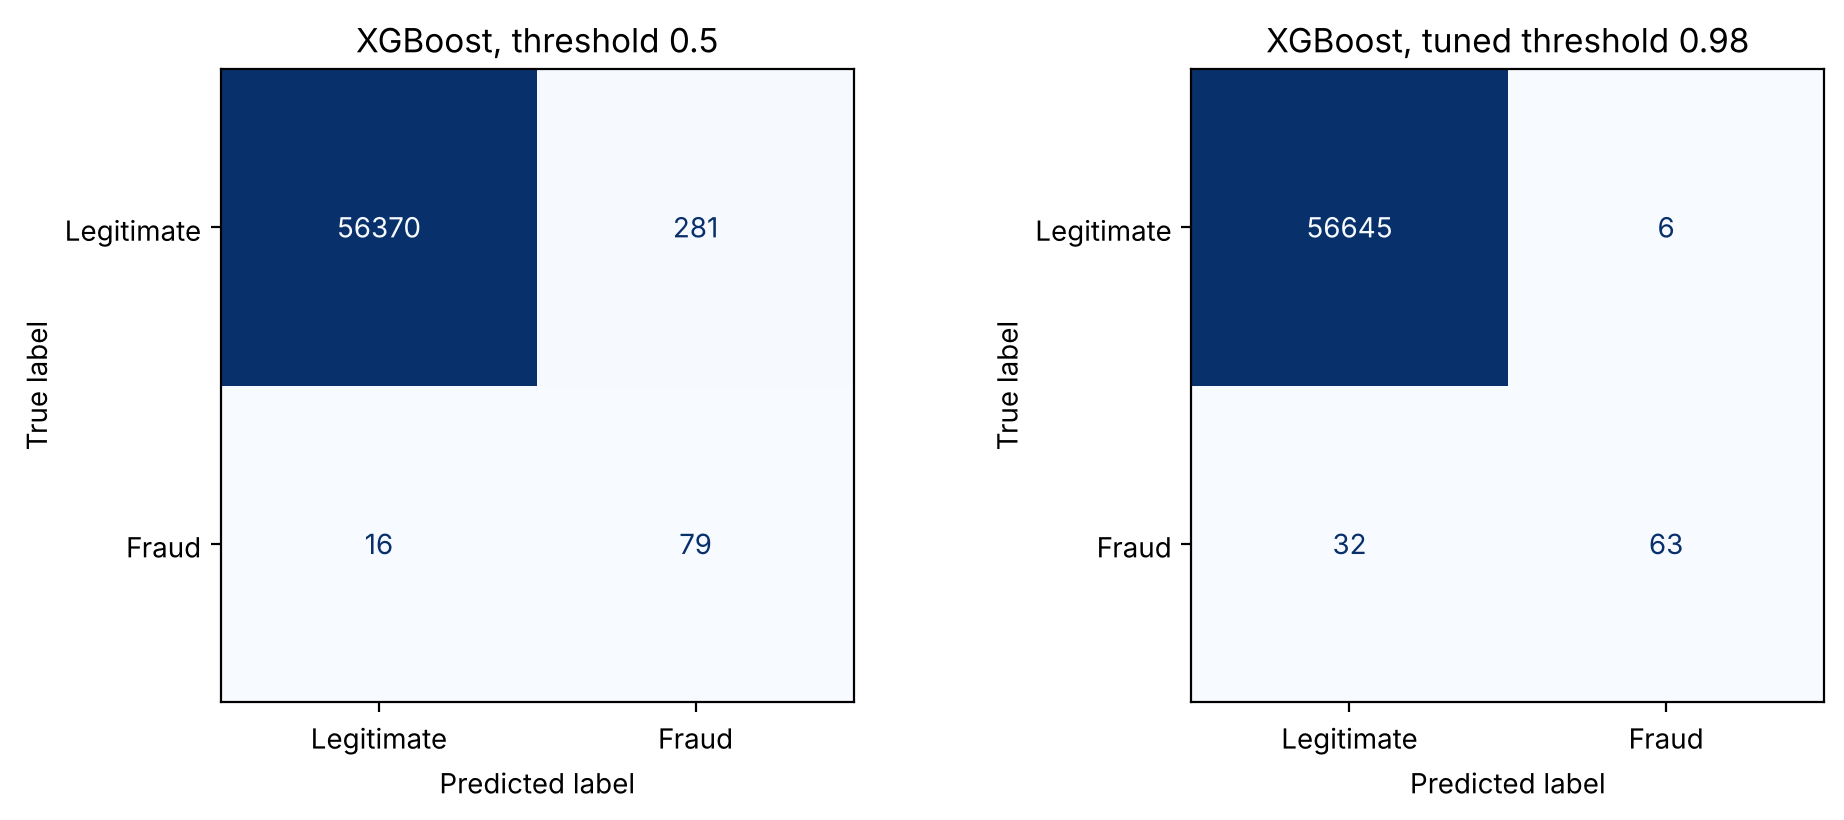

tuned threshold -> caught 63 of 95 frauds, 6 false alarms among 56,651 legitimate transactions


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
cms = {}
for ax, (title, t) in zip(axes, [("XGBoost, threshold 0.5", 0.5), (f"XGBoost, tuned threshold {THRESHOLD:.2f}", THRESHOLD)]):
    cm = confusion_matrix(y_test, (p_test >= t).astype(int)); cms[title] = cm.tolist()
    ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Fraud"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
plt.tight_layout(); plt.savefig(f"{OUT}/04_confusion_matrix.png", dpi=150); plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, (p_test >= THRESHOLD).astype(int)).ravel()
print(f"tuned threshold -> caught {tp} of {tp + fn} frauds, {fp} false alarms among {tn + fp:,} legitimate transactions")

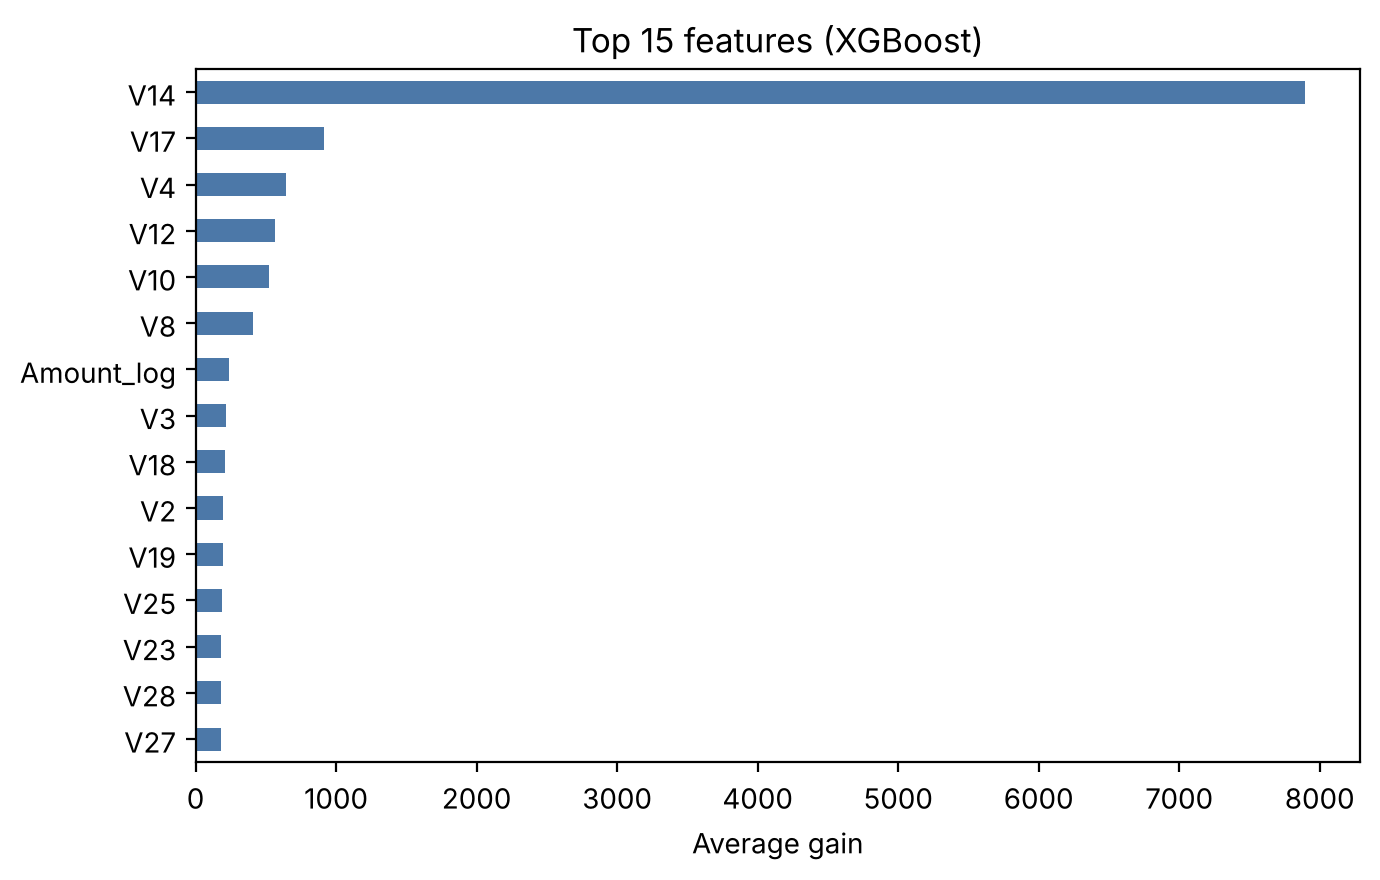

In [11]:
gain = pd.Series(xgb.get_booster().get_score(importance_type="gain")).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
gain[::-1].plot.barh(ax=ax, color="#4C78A8"); ax.set_xlabel("Average gain"); ax.set_title("Top 15 features (XGBoost)")
plt.tight_layout(); plt.savefig(f"{OUT}/05_feature_importance.png", dpi=150); plt.show()

## 6. Save the model, results and a small demo file for the Streamlit app

In [12]:
xgb.save_model(f"{MODELS}/xgb_fraud.json")
joblib.dump(scaler, f"{MODELS}/amount_scaler.joblib")

# demo transactions drawn from the TEST set (never used for training): 40 fraud + 160 legitimate
test_idx = X_test.index
frauds = df.loc[test_idx][df.loc[test_idx, "Class"] == 1].sample(40, random_state=SEED)
legit = df.loc[test_idx][df.loc[test_idx, "Class"] == 0].sample(160, random_state=SEED)
demo = pd.concat([frauds, legit]).sample(frac=1, random_state=SEED)[[f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]]
demo.to_csv(f"{DATA}/sample_transactions.csv", index=False)

meta = dict(
    dataset="Kaggle Credit Card Fraud Detection (mlg-ulb/creditcardfraud)",
    rows_raw=int(len(raw)), duplicates_removed=int(len(raw) - len(df)), rows_used=int(len(df)),
    fraud_total=int(df["Class"].sum()), train_rows=int(len(X_train)), test_rows=int(len(X_test)), test_fraud=int(y_test.sum()),
    features=FEATURES, threshold=THRESHOLD, xgb_best_iteration=int(xgb.best_iteration),
    metrics=results, confusion_matrices=cms,
    confusion_tuned=dict(TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp)))
json.dump(meta, open(f"{OUT}/results.json", "w"), indent=2)
print(json.dumps({k: meta[k] for k in ("rows_used", "fraud_total", "threshold", "confusion_tuned")}, indent=2))

{
  "rows_used": 283726,
  "fraud_total": 473,
  "threshold": 0.9759509563446045,
  "confusion_tuned": {
    "TN": 56645,
    "FP": 6,
    "FN": 32,
    "TP": 63
  }
}


## 7. Reading the results

* **Accuracy is meaningless here** (a model that never flags fraud scores about 99.8%), so use ROC-AUC, **average precision (PR-AUC)**, precision, recall and F1.
* The unsupervised models need no labels but are far weaker than the supervised XGBoost classifier. They are useful when no labelled fraud exists.
* Precision and recall trade off through the threshold: a lower threshold catches more fraud but raises false alarms. The right balance depends on the cost of a missed fraud versus a blocked legitimate purchase.
* The dataset is anonymized and covers only two days, and the split is random (stratified) rather than chronological, so real-world performance would be lower. Educational project, not a production fraud system.

In [13]:
# Bundle the model and charts for GitHub and download them (Colab)
import shutil
shutil.copy(f"{DATA}/sample_transactions.csv", f"{OUT}/sample_transactions.csv")
for name, folder in (("fraud_models", MODELS), ("fraud_outputs", OUT)):
    shutil.make_archive(name, "zip", root_dir=".", base_dir=folder)
try:
    from google.colab import files
    for z in ("fraud_models.zip", "fraud_outputs.zip"):
        files.download(z)
except ImportError:
    print("Not in Colab: the zips are in the working folder.")

Not in Colab: the zips are in the working folder.
